# AMASS with recomputed dynamics

`amass_dynamics` is the same OpenSim tree as `amass`, rerun through inverse dynamics with a fitted
floor and residual reporting. Kinematics are untouched -- positions, velocities and accelerations
match the original CSVs exactly -- only the `_tau` and ground-reaction columns change, plus eight
new ones (`*_ext_req`, `residual_force_bw`, `residual_moment_bwh`, `action`) the import ignores.
`recompute_report.csv` grades every take `good` / `ok` / `poor` on its residuals.

Imported under its own key, `source_dataset="AMASS-DYN"`, with the same representation as `AMASS`:
same channel layout, so views must filter on `source_datasets` to keep the two apart -- every
existing config already does. It gets its own pretraining split set (`poor` takes dropped) and its own stats file, so
`amass_clean`, `pretrain_v1` and every checkpoint stay exactly as they are.

The question this notebook answers: is the torque channel better than the one `amass_clean`
trains on? Kinematics being identical, any difference between the arms *is* the dynamics.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch as t

from sometria.babel import import_babel_annotations, import_babel_splits
from sometria.catalog import (
    SPLITS,
    MotionViewSpec,
    build_motion_view,
    create_pretrain_split,
    load_catalog,
    load_splits,
    normalization_path,
    sample_key,
    upsert_table,
)
from sometria.normalization import save_feature_normalization
from sometria.preprocess import TAU_RATE_MAX, ImportConfig, import_opensim_csv_dataset
from sometria.representation import Representation, _load_human_definition

In [2]:
RAW_AMASS = Path("/home/z1ko/datasets/sometria/amass")
RAW_DYNAMICS = Path("/home/z1ko/datasets/sometria/amass_dynamics")
RAW_BABEL = Path("/home/z1ko/datasets/sometria/babel")
OUT = Path("../data/processed")

ARMS = ("AMASS", "AMASS-DYN")
PRETRAIN_SPLIT = "pretrain_dyn_v1"
BABEL_SPLIT = "babel_dyn_v1"
NORMALIZATION_NAME = f"{PRETRAIN_SPLIT}_train_clean"
WINDOW_FRAMES = 240

HUMAN = _load_human_definition("../config/human.yaml")
REPRESENTATION = Representation.from_human(HUMAN)
print(REPRESENTATION)

Representation('opensim_sincos_log_vel_acc_tau_v2', 43 dofs, 5 channels)


## Import

Pattern is `*/**/*.csv`, not `**/*.csv`: the report sits at the root of the tree and is not a take.
BABEL importers are re-run so the new rows land on the official splits too; they rewrite the splits
and annotations tables with the same values for rows that already existed. Expect the collision
warning -- `AMASS` and `AMASS-DYN` share every take key by construction.

In [3]:
catalog = import_opensim_csv_dataset(
    config=ImportConfig(
        source_dataset="AMASS-DYN",
        input_root=RAW_DYNAMICS,
        output_root=OUT,
        pattern="*/**/*.csv",
    ),
    human=HUMAN,
    representation=REPRESENTATION,
)

  0%|          | 0/17453 [00:00<?, ?it/s]

  0%|          | 2/17453 [00:00<15:49, 18.38it/s]

  0%|          | 5/17453 [00:00<12:20, 23.57it/s]

  0%|          | 8/17453 [00:00<11:29, 25.30it/s]

  0%|          | 11/17453 [00:00<11:35, 25.07it/s]

...

100%|█████████▉| 17442/17453 [08:42<00:00, 39.26it/s]

100%|█████████▉| 17446/17453 [08:42<00:00, 38.12it/s]

100%|█████████▉| 17450/17453 [08:42<00:00, 38.07it/s]

100%|██████████| 17453/17453 [08:42<00:00, 33.41it/s]

shape: (3, 3)
┌────────────────┬───────┬────────┐
│ source_dataset ┆ len   ┆ broken │
│ ---            ┆ ---   ┆ ---    │
│ str            ┆ u32   ┆ u32    │
╞════════════════╪═══════╪════════╡
│ AMASS          ┆ 17453 ┆ 809    │
│ AMASS-DYN      ┆ 17453 ┆ 211    │
│ MotionX        ┆ 52291 ┆ 25404  │
└────────────────┴───────┴────────┘


In [3]:
import_babel_splits(babel_root=RAW_BABEL, output_root=OUT)
import_babel_annotations(babel_root=RAW_BABEL, output_root=OUT)

print(
    load_catalog(OUT)
    .group_by("source_dataset").agg(pl.len(), pl.col("broken").sum())
    .sort("source_dataset")
)

shape: (3, 3)
┌────────────────┬───────┬────────┐
│ source_dataset ┆ len   ┆ broken │
│ ---            ┆ ---   ┆ ---    │
│ str            ┆ u32   ┆ u32    │
╞════════════════╪═══════╪════════╡
│ AMASS          ┆ 17453 ┆ 809    │
│ AMASS-DYN      ┆ 17453 ┆ 211    │
│ MotionX        ┆ 52291 ┆ 25404  │
└────────────────┴───────┴────────┘


## Paired per take

One row per take with both arms' quality side by side, plus the residual report. The report names
files under `amass/`, the catalog under `amass_dynamics/`; both reduce to the same `sample_key`.

In [4]:
def arm(name: str) -> pl.DataFrame:
    return (
        load_catalog(OUT)
        .filter(pl.col("source_dataset") == name)
        .select(
            pl.col("source_path").map_elements(sample_key, return_dtype=pl.String).alias("take"),
            "source_subset",
            pl.col("metadata").struct.field("subject_mass_kg").alias("mass"),
            "duration",
            "tau_rate",
            "tau_absmax",
            "broken",
        )
    )


report = pl.read_csv(RAW_DYNAMICS / "recompute_report.csv").select(
    pl.col("file")
    .map_elements(lambda f: sample_key(str(Path(f).relative_to(RAW_AMASS))), return_dtype=pl.String)
    .alias("take"),
    "quality",
    "residual_force_med_bw",
    "residual_force_p95_bw",
    "residual_moment_med_bwh",
    "joint_tau_p99_nm_per_kg",
)

paired = (
    arm("AMASS")
    .join(arm("AMASS-DYN").drop("source_subset", "mass", "duration"), on="take", suffix="_dyn")
    .join(report, on="take", how="left")
    .with_columns(
        (pl.col("tau_absmax") / pl.col("mass")).alias("tau_absmax_kg"),
        (pl.col("tau_absmax_dyn") / pl.col("mass")).alias("tau_absmax_kg_dyn"),
    )
)
print(f"{len(paired):,} takes in both arms, {paired['quality'].null_count()} without a report row")

print(
    paired.select(
        pl.len().alias("takes"),
        pl.col("broken").sum().alias("broken_amass"),
        pl.col("broken_dyn").sum().alias("broken_dyn"),
        (pl.col("broken") & ~pl.col("broken_dyn")).sum().alias("fixed"),
        (~pl.col("broken") & pl.col("broken_dyn")).sum().alias("newly_broken"),
        (pl.col("tau_rate_dyn") < pl.col("tau_rate")).mean().round(3).alias("smoother_share"),
        (pl.col("tau_absmax_kg_dyn") < pl.col("tau_absmax_kg")).mean().round(3).alias("lower_peak_share"),
    )
)
print(paired.select(
    pl.col("tau_rate", "tau_rate_dyn", "tau_absmax_kg", "tau_absmax_kg_dyn")
).describe(percentiles=(0.5, 0.9, 0.99)))

17,675 takes in both arms, 0 without a report row
shape: (1, 7)
┌───────┬──────────────┬────────────┬───────┬──────────────┬────────────────┬──────────────────┐
│ takes ┆ broken_amass ┆ broken_dyn ┆ fixed ┆ newly_broken ┆ smoother_share ┆ lower_peak_share │
│ ---   ┆ ---          ┆ ---        ┆ ---   ┆ ---          ┆ ---            ┆ ---              │
│ u32   ┆ u32          ┆ u32        ┆ u32   ┆ u32          ┆ f64            ┆ f64              │
╞═══════╪══════════════╪════════════╪═══════╪══════════════╪════════════════╪══════════════════╡
│ 17675 ┆ 812          ┆ 214        ┆ 603   ┆ 5            ┆ 0.963          ┆ 0.989            │
└───────┴──────────────┴────────────┴───────┴──────────────┴────────────────┴──────────────────┘
shape: (9, 5)
┌────────────┬──────────────┬──────────────┬───────────────┬───────────────────┐
│ statistic  ┆ tau_rate     ┆ tau_rate_dyn ┆ tau_absmax_kg ┆ tau_absmax_kg_dyn │
│ ---        ┆ ---          ┆ ---          ┆ ---           ┆ ---               │


### Torque discontinuity and peak, arm against arm

`tau_rate` is max |dtau/dt| over the take, the number `broken` thresholds; `tau_absmax` per kg is
the peak joint torque normalized by body mass. Points under the diagonal improved.

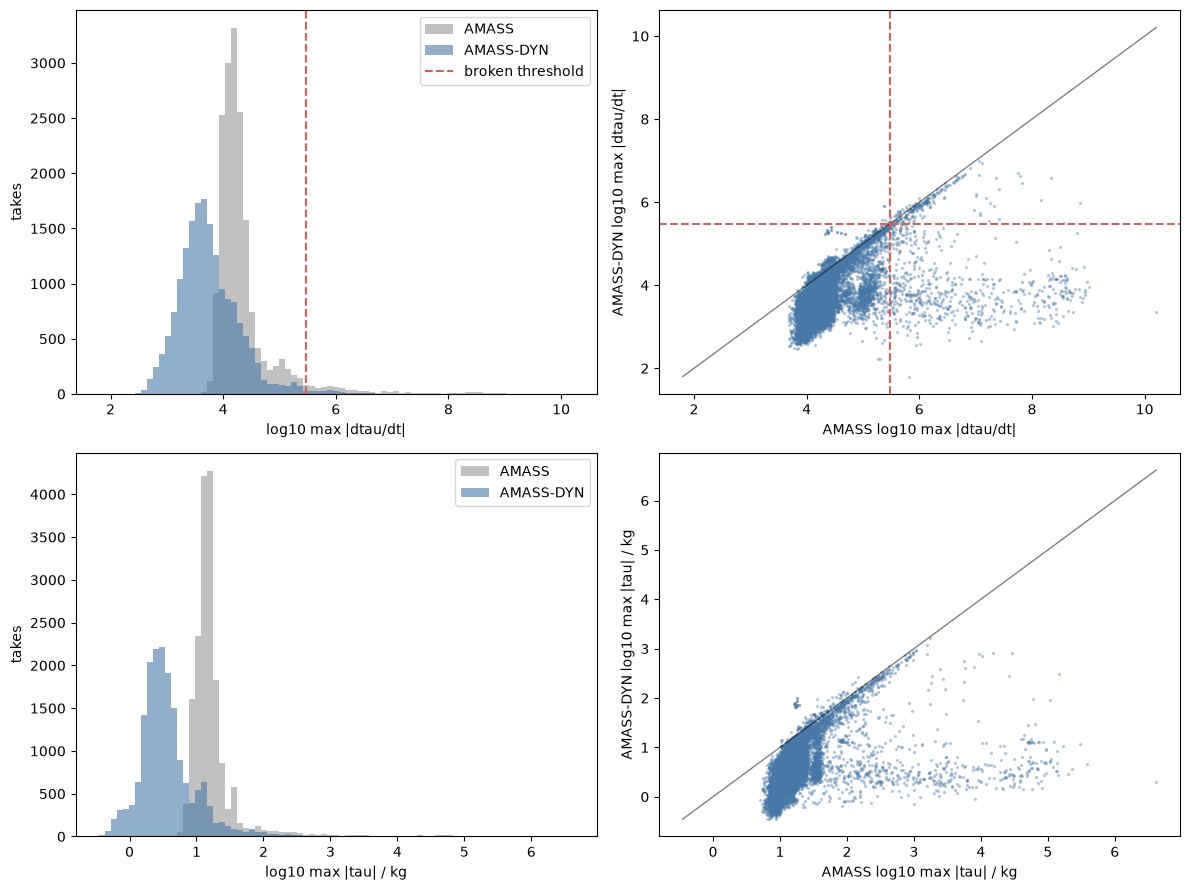

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

for col, label, threshold, row in [
    ("tau_rate", "log10 max |dtau/dt|", np.log10(TAU_RATE_MAX), 0),
    ("tau_absmax_kg", "log10 max |tau| / kg", None, 1),
]:
    old = np.log10(paired[col].to_numpy().clip(1e-3))
    new = np.log10(paired[f"{col}_dyn"].to_numpy().clip(1e-3))
    bins = np.linspace(min(old.min(), new.min()), max(old.max(), new.max()), 80)

    ax[row, 0].hist(old, bins=bins, alpha=0.6, color="#999999", label="AMASS")
    ax[row, 0].hist(new, bins=bins, alpha=0.6, color="#4878a8", label="AMASS-DYN")
    ax[row, 0].set(xlabel=label, ylabel="takes")
    ax[row, 0].legend()

    ax[row, 1].scatter(old, new, s=2, alpha=0.3, color="#4878a8")
    lo, hi = bins[0], bins[-1]
    ax[row, 1].plot([lo, hi], [lo, hi], color="black", linewidth=1, alpha=0.5)
    ax[row, 1].set(xlabel=f"AMASS {label}", ylabel=f"AMASS-DYN {label}")

    if threshold is not None:
        ax[row, 0].axvline(threshold, color="#d1615d", linestyle="--", label="broken threshold")
        ax[row, 1].axvline(threshold, color="#d1615d", linestyle="--")
        ax[row, 1].axhline(threshold, color="#d1615d", linestyle="--")
        ax[row, 0].legend()

fig.tight_layout()

### Broken rate by subset

shape: (26, 6)
┌───────────────┬──────┬────────────┬────────────────┬──────────┬──────────────────┐
│ source_subset ┆ n    ┆ broken_pct ┆ broken_pct_dyn ┆ poor_pct ┆ res_force_med_bw │
│ ---           ┆ ---  ┆ ---        ┆ ---            ┆ ---      ┆ ---              │
│ str           ┆ u32  ┆ f64        ┆ f64            ┆ f64      ┆ f64              │
╞═══════════════╪══════╪════════════╪════════════════╪══════════╪══════════════════╡
│ KIT           ┆ 4147 ┆ 0.48       ┆ 0.41           ┆ 8.66     ┆ 0.0              │
│ BMLrub        ┆ 2992 ┆ 0.47       ┆ 0.4            ┆ 5.65     ┆ 0.0              │
│ WEIZMANN      ┆ 1947 ┆ 0.72       ┆ 0.62           ┆ 6.57     ┆ 0.01             │
│ CMU           ┆ 1878 ┆ 21.99      ┆ 1.06           ┆ 13.37    ┆ 0.0              │
│ BMLmovi       ┆ 1858 ┆ 1.18       ┆ 1.13           ┆ 1.88     ┆ 0.0              │
│ …             ┆ …    ┆ …          ┆ …              ┆ …        ┆ …                │
│ TotalCapture  ┆ 31   ┆ 16.13      ┆ 3.23        

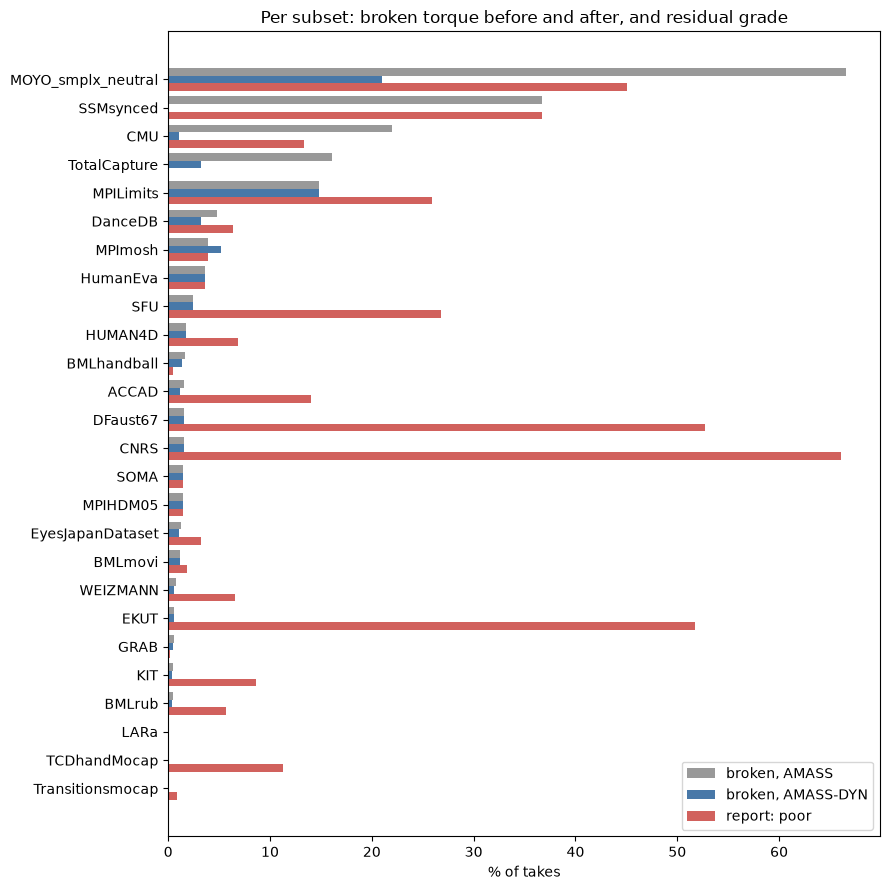

In [6]:
by_subset = (
    paired.group_by("source_subset")
    .agg(
        pl.len().alias("n"),
        (100 * pl.col("broken").mean()).alias("broken_pct"),
        (100 * pl.col("broken_dyn").mean()).alias("broken_pct_dyn"),
        (100 * (pl.col("quality") == "poor").mean()).alias("poor_pct"),
        pl.col("residual_force_med_bw").median().alias("res_force_med_bw"),
    )
    .sort("n", descending=True)
)
print(by_subset.with_columns(pl.col(pl.Float64).round(2)))

top = by_subset.sort("broken_pct")
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(y + 0.27, top["broken_pct"], height=0.27, color="#999999", label="broken, AMASS")
ax.barh(y, top["broken_pct_dyn"], height=0.27, color="#4878a8", label="broken, AMASS-DYN")
ax.barh(y - 0.27, top["poor_pct"], height=0.27, color="#d1615d", label="report: poor")
ax.set_yticks(y, top["source_subset"])
ax.set(xlabel="% of takes", title="Per subset: broken torque before and after, and residual grade")
ax.legend()
fig.tight_layout()

## Residual report against our `broken` flag

The two checks measure different failures: `broken` is a torque discontinuity, the report grades how
much external force and moment the pelvis needed to make the dynamics consistent. A take can be
smooth and physically implausible, or the reverse. `poor` takes leave the pretraining
split below.

shape: (3, 5)
┌─────────┬───────┬───────┬──────────────┬────────────┐
│ quality ┆ takes ┆ hours ┆ broken_amass ┆ broken_dyn │
│ ---     ┆ ---   ┆ ---   ┆ ---          ┆ ---        │
│ str     ┆ u32   ┆ f64   ┆ u32          ┆ u32        │
╞═════════╪═══════╪═══════╪══════════════╪════════════╡
│ good    ┆ 14445 ┆ 34.0  ┆ 484          ┆ 34         │
│ ok      ┆ 1573  ┆ 3.1   ┆ 71           ┆ 24         │
│ poor    ┆ 1657  ┆ 3.9   ┆ 257          ┆ 156        │
└─────────┴───────┴───────┴──────────────┴────────────┘


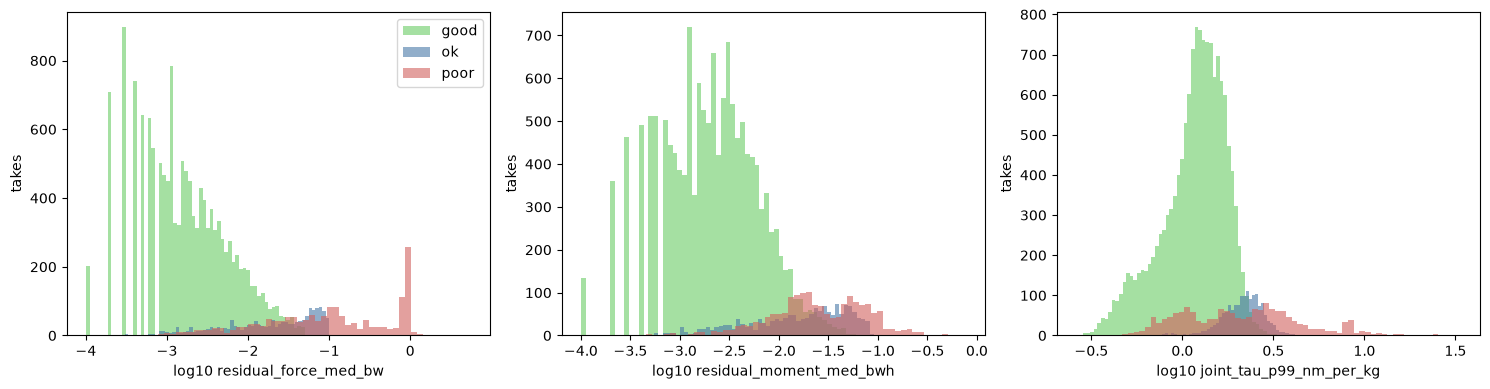

In [7]:
print(
    paired.group_by("quality")
    .agg(
        pl.len().alias("takes"),
        (pl.col("duration").sum() / 3600).round(1).alias("hours"),
        pl.col("broken").sum().alias("broken_amass"),
        pl.col("broken_dyn").sum().alias("broken_dyn"),
    )
    .sort("quality")
)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colors = {"good": "#6acc64", "ok": "#4878a8", "poor": "#d1615d"}
for grade, color in colors.items():
    sub = paired.filter(pl.col("quality") == grade)
    for i, col in enumerate(["residual_force_med_bw", "residual_moment_med_bwh", "joint_tau_p99_nm_per_kg"]):
        ax[i].hist(np.log10(sub[col].to_numpy().clip(1e-4)), bins=60, alpha=0.6, color=color, label=grade)
        ax[i].set(xlabel=f"log10 {col}", ylabel="takes")
ax[0].legend()
fig.tight_layout()

## One take, both torques

The take where the two arms disagree most on `tau_rate`, read straight from both CSVs. Joint
angles are shared, so only the torque traces are drawn.

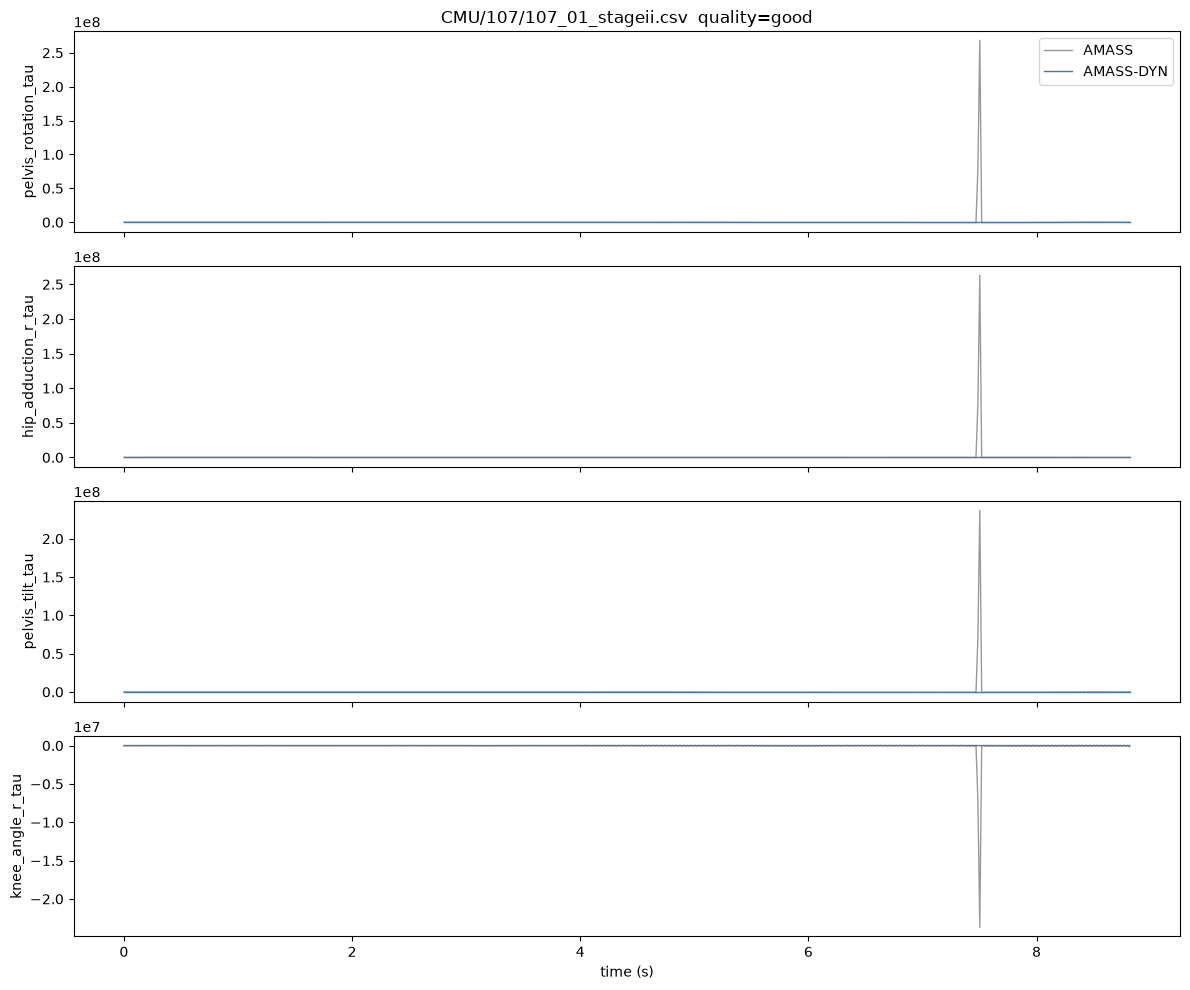

In [8]:
worst = paired.sort(pl.col("tau_rate") / pl.col("tau_rate_dyn"), descending=True).row(0, named=True)
match = [
    p for p in RAW_DYNAMICS.glob(f"{worst['source_subset']}/**/*.csv")
    if sample_key(str(p.relative_to(RAW_DYNAMICS))) == worst["take"]
][0]
old = pl.read_csv(RAW_AMASS / match.relative_to(RAW_DYNAMICS))
new = pl.read_csv(match)

taus = [f"{dof}_tau" for dof in HUMAN["dofs"]]
dofs = sorted(taus, key=lambda c: -np.abs(old[c].to_numpy() - new[c].to_numpy()).max())[:4]

fig, ax = plt.subplots(len(dofs), 1, figsize=(12, 2.5 * len(dofs)), sharex=True)
for a, dof in zip(ax, dofs):
    a.plot(old["time"], old[dof], color="#999999", linewidth=1, label="AMASS")
    a.plot(new["time"], new[dof], color="#4878a8", linewidth=1, label="AMASS-DYN")
    a.set_ylabel(dof)
ax[0].legend()
ax[0].set_title(f"{match.relative_to(RAW_DYNAMICS)}  quality={worst['quality']}")
ax[-1].set_xlabel("time (s)")
fig.tight_layout()

## Pretraining split, without `poor` takes

Same policy as `pretrain_v1` -- BABEL train plus everything BABEL never saw -- on the new arm
only, minus every take the report grades `poor`. Matched on the exact source path, not the lossy
take key, so a collision cannot drop a good take. The filter lives in the split rather than the
catalog: `broken` is measured at ingest from the raw motion, the grade is this corpus's own report.
BABEL's official splits keep their `poor` takes; `babel_dyn_v1` is their copy without them, so
validation loss is not measured on torques the report already rejected.

In [9]:
poor = (
    pl.read_csv(RAW_DYNAMICS / "recompute_report.csv")
    .filter(pl.col("quality") == "poor")
    .select(
        pl.col("file")
        .map_elements(lambda f: f"AMASS-DYN:{Path(f).relative_to(RAW_AMASS)}", return_dtype=pl.String)
        .alias("sample_id")
    )
    .join(load_catalog(OUT).select("sample_id"), on="sample_id", how="semi")
)
print(f"{len(poor):,} poor takes matched to catalog rows")

create_pretrain_split(
    output_root=OUT,
    split_set=PRETRAIN_SPLIT,
    source_datasets=("AMASS-DYN",),
    exclude=tuple(poor["sample_id"]),
)

1,534 poor takes matched to catalog rows


sample_id,split_set,split,label_source,babel_sid
str,str,str,str,i64
"""MotionX:music/subset_0016/Play…","""pretrain_v2""","""train""",null,null
"""MotionX:game_motion/subset_001…","""pretrain_v2""","""train""",null,null
"""AMASS-DYN:EyesJapanDataset/kaw…","""pretrain_dyn_v1""","""train""",null,null
"""MotionX:idea400/subset_0057/Si…","""pretrain_v2""","""train""",null,null
"""AMASS:WEIZMANN/67/Mixed_SlowFa…","""pretrain_v1""","""train""",null,null
…,…,…,…,…
"""AMASS:GRAB/s5/mouse_pass_1_sta…","""pretrain_v1""","""train""",null,null
"""MotionX:game_motion/subset_001…","""pretrain_v2""","""train""",null,null
"""MotionX:game_motion/subset_003…","""pretrain_v2""","""train""",null,null


In [10]:
babel_dyn = (
    load_splits(OUT)
    .filter((pl.col("split_set") == "babel_official") & pl.col("sample_id").str.starts_with("AMASS-DYN:"))
    .join(poor, on="sample_id", how="anti")
    .with_columns(pl.lit(BABEL_SPLIT).alias("split_set"))
)
upsert_table(OUT, SPLITS, babel_dyn, keys=["sample_id", "split_set"])
print(babel_dyn.group_by("split").len().sort("split"))

shape: (3, 2)
┌───────┬──────┐
│ split ┆ len  │
│ ---   ┆ ---  │
│ str   ┆ u32  │
╞═══════╪══════╡
│ test  ┆ 1828 │
│ train ┆ 5791 │
│ val   ┆ 1908 │
└───────┴──────┘


## Normalization

Compared against the `amass_clean` stats: kinematic channels should stay close, since the views
differ only by which takes `broken` and `poor` drop; `tau` is where they part.

  0%|          | 0/12129 [00:00<?, ?it/s]

  1%|          | 63/12129 [00:00<00:19, 628.01it/s]

  1%|▏         | 168/12129 [00:00<00:13, 874.24it/s]

  2%|▏         | 257/12129 [00:00<00:13, 879.02it/s]

  3%|▎         | 356/12129 [00:00<00:12, 920.12it/s]

...

 98%|█████████▊| 11859/12129 [00:14<00:00, 1037.77it/s]

 99%|█████████▊| 11964/12129 [00:14<00:00, 1037.37it/s]

 99%|█████████▉| 12068/12129 [00:14<00:00, 1011.25it/s]

100%|██████████| 12129/12129 [00:14<00:00, 846.49it/s] 

12,129 takes  27.7 h  ->  ../data/processed/stats/opensim_sincos_log_vel_acc_tau_v2/pretrain_dyn_v1_train_clean.pt


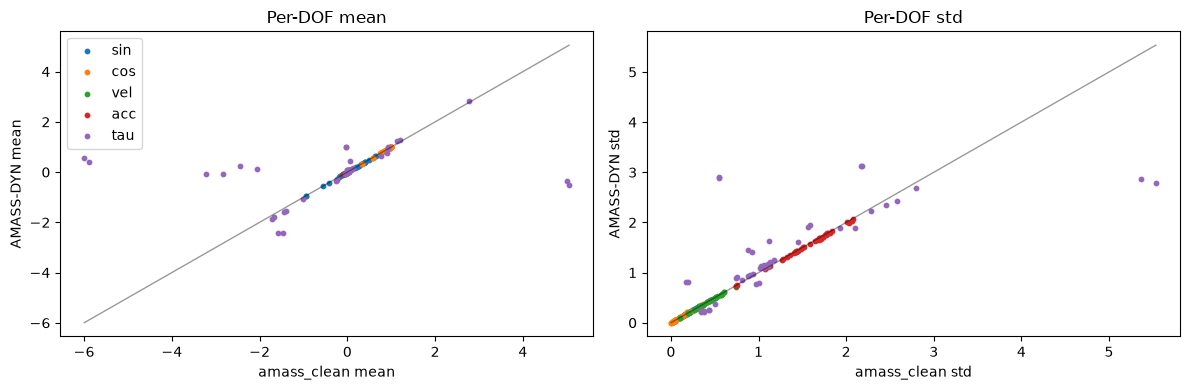

In [11]:
spec = MotionViewSpec(
    representation=REPRESENTATION.name,
    split_set=PRETRAIN_SPLIT,
    split="train",
    source_datasets=("AMASS-DYN",),
    exclude_broken=True,
)
view = build_motion_view(OUT, spec)
path = save_feature_normalization(
    output_root=OUT, samples=view, name=NORMALIZATION_NAME, representation=REPRESENTATION, spec=spec,
)
print(f"{len(view):,} takes  {view['duration'].sum() / 3600:.1f} h  ->  {path}")

dyn = t.load(path, weights_only=True)
clean = t.load(normalization_path(OUT, REPRESENTATION.name, "pretrain_v1_train_clean"), weights_only=True)
names = list(REPRESENTATION.channels)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, stat in enumerate(("mean", "std")):
    a, b = clean[stat].squeeze(0).numpy(), dyn[stat].squeeze(0).numpy()
    for channel, name in enumerate(names):
        ax[i].scatter(a[:, channel], b[:, channel], s=10, label=name)
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ax[i].plot([lo, hi], [lo, hi], color="black", linewidth=1, alpha=0.4)
    ax[i].set(xlabel=f"amass_clean {stat}", ylabel=f"AMASS-DYN {stat}", title=f"Per-DOF {stat}")
ax[0].legend()
fig.tight_layout()

## Training on it

```
uv run python train.py --config config/pretrain_mae.yaml config/dataloader/amass_dynamics.yaml config/mae/medium.yaml --output runs/pretrain/amass_dynamics/medium_100ep
```